In [ ]:
pip install requests pandas matplotlib

Status: 200
               País      Casos   Mortes  Recuperados
218  Estados Unidos  111820082  1219487    109814428
94            Índia   45035393   533570            0
71           França   40138560   167642     39970918
77         Alemanha   38828995   183027     38240600
26           Brasil   38743918   711380     36249161
171        S. Korea   34571873    35934     34535939
103           Japão   33803572    74694            0
101          Itália   26723249   196487     26361218
217     Reino Unido   24910387   232112     24678275
168          Rússia   24124215   402756     23545818


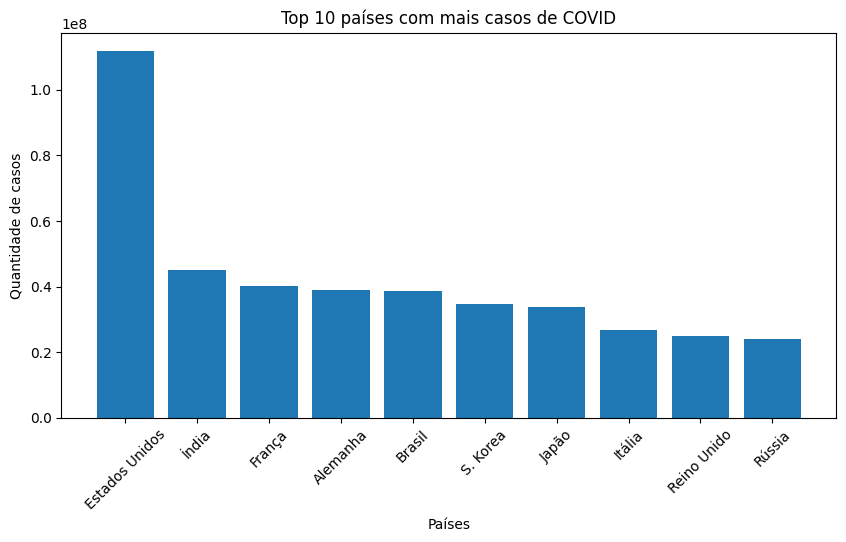

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://disease.sh/v3/covid-19/countries"
response = requests.get(url)
print("Status:", response.status_code)

dados = response.json()
df = pd.DataFrame(dados)

df = df.rename(columns={
    "country": "País",
    "cases": "Casos",
    "deaths": "Mortes",
    "recovered": "Recuperados",
})

df = df.dropna()
top10 = df.sort_values(by="Casos", ascending=False).head(10)

traducoes = {
    "USA": "Estados Unidos",
    "India": "Índia",
    "France": "França",
    "Germany": "Alemanha",
    "Brazil": "Brasil",
    "Japan": "Japão",
    "South Korea": "Coreia do Sul",
    "Italy": "Itália",
    "UK": "Reino Unido",
    "Russia": "Rússia"
}

top10["País"] = top10["País"].replace(traducoes)
print(top10[["País", "Casos", "Mortes", "Recuperados"]])

plt.figure(figsize=(10,5))
plt.bar(top10["País"], top10["Casos"])
plt.xticks(rotation=45)
plt.title("Top 10 países com mais casos de COVID")
plt.ylabel("Quantidade de casos")
plt.xlabel("Países")

plt.show()